# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

In [3]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [4]:
import sys

In [19]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cpu


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [21]:
torch.set_num_threads(24)

### Exercise 1 — Answers

**Q1. What is CLIP?**

CLIP (Contrastive Language–Image Pre-training) is a vision-language model developed by OpenAI. It learns relationships between images and natural-language descriptions by mapping them into a shared embedding space. This allows tasks such as image-text similarity and zero-shot image classification.

**Q2. What are its two main components?**

CLIP consists of two main components:

- **Image encoder:** Extracts visual features from an image and represents them as a numerical vector.
- **Text encoder:** Converts a text description into a numerical vector.

Both representations can be compared in a shared embedding space.

**Q3. What is the role of `CLIPProcessor`?**

`CLIPProcessor` prepares images and text for the model. It resizes, crops and normalizes images, while tokenizing and padding text as needed. It returns the input tensors expected by CLIP.

**Q4. What is the role of `CLIPModel`?**

`CLIPModel` contains the pretrained image and text encoders and their projection layers. It generates image and text representations and computes similarity scores between them, allowing the model to identify which descriptions best match an image.

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Image size: (1546, 1213)
Image mode: RGB


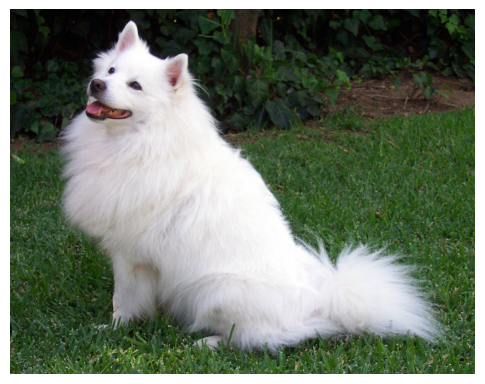

In [3]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "image.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

### Exercise 2 — Answers

**Q5. What is the size of the image?**

The image size is **1546 × 1213 pixels** (width × height).

**Q6. What type of data is stored in the PIL image object?**

The PIL image object stores **raster image data**, represented as a two-dimensional grid of pixels. Since the image was converted to **RGB mode**, each pixel contains three color-channel values: **Red, Green, and Blue**, typically ranging from 0 to 255. These values represent the color information used for image processing and analysis.

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [4]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.0038
a photo of a dog                   : 0.9876
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0057
a photo of a person                : 0.0028


### Exercise 3 — Answers

**Q7. Which description has the highest probability?**

The description **"a photo of a dog"** is expected to have the highest probability because the input image contains a dog.

**Q8. Is it compatible with the actual image?**

Yes. The description **"a photo of a dog"** correctly represents the content of the input image. This demonstrates CLIP's ability to associate visual information with relevant natural-language descriptions.

**Q9. Why can CLIP compare an image with a sentence?**

CLIP uses two pretrained encoders: an **image encoder** and a **text encoder**. Both transform their respective inputs into numerical representations within a **shared embedding space**. By measuring the similarity between these representations, CLIP can determine how closely an image matches a textual description.

**Q10. What does `softmax()` do?**

The `softmax()` function transforms the model's similarity scores (logits) into a **probability distribution**. Each resulting value is between 0 and 1, and the probabilities across all candidate descriptions sum to 1.

This makes it easier to compare the relative likelihood of different descriptions. These probabilities are relative to the provided candidates and are not necessarily calibrated confidence scores.

## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [5]:
def classify_image(image, labels):
    # Convert category names into text descriptions
    texts = [f"a photo of a {label}" for label in labels]

    # Prepare image and text inputs
    inputs = processor(
        text=texts,
        images=image,
        return_tensors="pt",
        padding=True
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Run CLIP inference
    with torch.no_grad():
        outputs = model(**inputs)

    # Convert similarity scores into probabilities
    probabilities = outputs.logits_per_image.softmax(dim=1)[0]

    # Find the most likely category
    best_index = probabilities.argmax().item()

    return labels[best_index], probabilities.cpu()


# Test the function
labels = ["cat", "dog", "car", "horse", "person"]

predicted_label, probabilities = classify_image(image, labels)

print("Predicted class:", predicted_label)

for label, probability in zip(labels, probabilities):
    print(f"{label:10s}: {probability.item():.4f}")

Predicted class: dog
cat       : 0.0038
dog       : 0.9876
car       : 0.0001
horse     : 0.0057
person    : 0.0028


### Exercise 4 — Answers

**Q11. What is zero-shot classification?**

Zero-shot classification is a machine learning technique that allows a pretrained model to **classify images into categories without requiring labeled training examples for those specific categories**. CLIP achieves this by comparing image representations with natural-language descriptions in a **shared embedding space**.

**Q12. Why is it not necessary to train a new classifier?**

It is not necessary to train a new classifier because **CLIP has already learned relationships between images and text during its pretraining**. Its image and text encoders can compare new images with arbitrary candidate class descriptions using similarity scores. Therefore, new categories can be introduced simply by changing the text prompts, **without retraining or fine-tuning the model**.

**Q13. What happens if the correct class is not included in the candidate classes?**

If the correct class is missing from the candidate classes, CLIP will still select the **most similar class among the available options**, even if none correctly describes the image. This can lead to **incorrect or misleading predictions**, because the model is forced to choose from the provided categories. A possible solution is to introduce an **unknown-class rejection mechanism** based on similarity thresholds, although such thresholds require validation.

## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [6]:
import requests
from pathlib import Path
from PIL import Image
from io import BytesIO

folder = Path("images/evaluation")
folder.mkdir(parents=True, exist_ok=True)

dataset = []

# Download 5 cat images
for i in range(5):
    response = requests.get(
        "https://cataas.com/cat",
        params={"width": 400, "height": 400, "t": i},
        timeout=30
    )
    response.raise_for_status()

    img = Image.open(BytesIO(response.content)).convert("RGB")
    path = folder / f"cat{i+1}.jpg"
    img.save(path)

    dataset.append((str(path), "cat"))

# Download 5 dog images
dog_api = requests.get(
    "https://dog.ceo/api/breeds/image/random/5",
    timeout=30
)
dog_api.raise_for_status()

for i, url in enumerate(dog_api.json()["message"], start=1):
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    img = Image.open(BytesIO(response.content)).convert("RGB")
    path = folder / f"dog{i}.jpg"
    img.save(path)

    dataset.append((str(path), "dog"))

print("Total images:", len(dataset))
print(dataset)

Total images: 10
[('images/evaluation/cat1.jpg', 'cat'), ('images/evaluation/cat2.jpg', 'cat'), ('images/evaluation/cat3.jpg', 'cat'), ('images/evaluation/cat4.jpg', 'cat'), ('images/evaluation/cat5.jpg', 'cat'), ('images/evaluation/dog1.jpg', 'dog'), ('images/evaluation/dog2.jpg', 'dog'), ('images/evaluation/dog3.jpg', 'dog'), ('images/evaluation/dog4.jpg', 'dog'), ('images/evaluation/dog5.jpg', 'dog')]


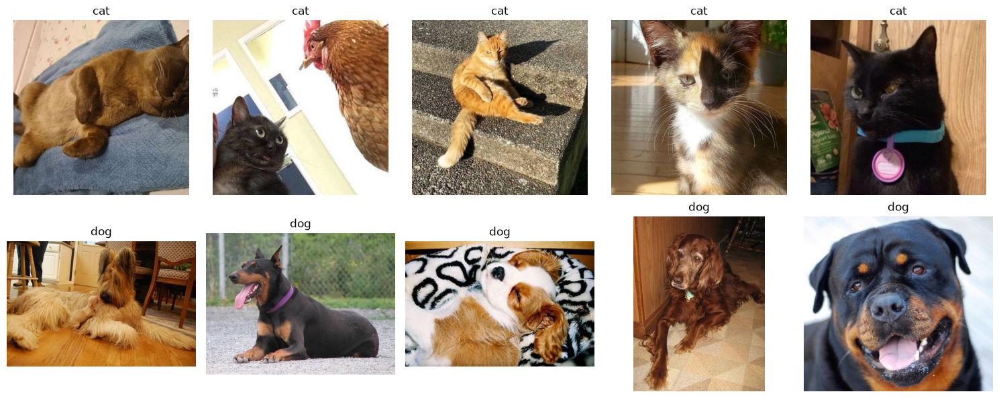

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, (path, label) in zip(axes.flat, dataset):
    ax.imshow(Image.open(path))
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import pandas as pd
import torch
from PIL import Image

model.eval()
classes = ["cat", "dog"]
results = []

for image_path, actual_class in dataset:
    img = Image.open(image_path).convert("RGB")

    texts = [f"a photo of a {c}" for c in classes]
    inputs = processor(
        text=texts,
        images=img,
        return_tensors="pt",
        padding=True
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        probs = outputs.logits_per_image.softmax(dim=1)[0]

    best_idx = probs.argmax().item()
    predicted_class = classes[best_idx]
    probability = probs[best_idx].item()

    results.append({
        "Image": image_path,
        "Actual": actual_class,
        "Predicted": predicted_class,
        "Probability": round(probability, 4),
        "Correct": predicted_class == actual_class
    })

df = pd.DataFrame(results)

accuracy = df["Correct"].mean()

display(df)
print(f"\nAccuracy: {accuracy:.2%}")
print(f"Correct predictions: {df['Correct'].sum()}/{len(df)}")

print("\nIncorrectly classified images:")
display(df[df["Correct"] == False])

,Image,Actual,Predicted,Probability,Correct
0,images/evaluation/cat1.jpg,cat,cat,0.9947,True
1,images/evaluation/cat2.jpg,cat,cat,0.9801,True
2,images/evaluation/cat3.jpg,cat,cat,0.9859,True
3,images/evaluation/cat4.jpg,cat,cat,0.9980,True
4,images/evaluation/cat5.jpg,cat,cat,0.9927,True
5,images/evaluation/dog1.jpg,dog,dog,0.9973,True
6,images/evaluation/dog2.jpg,dog,dog,0.9990,True
7,images/evaluation/dog3.jpg,dog,dog,0.9815,True
8,images/evaluation/dog4.jpg,dog,dog,0.9989,True
9,images/evaluation/dog5.jpg,dog,dog,0.9993,True



Accuracy: 100.00%
Correct predictions: 10/10

Incorrectly classified images:


,Image,Actual,Predicted,Probability,Correct


### Exercise 5 — Answers

**Q14. What is the obtained accuracy?**

The obtained classification accuracy is **100%**, with **10 correctly classified images out of 10**.

**Q15. Which images are incorrectly classified?**

**None of the images were incorrectly classified.** All 10 images received the correct predicted label, resulting in **zero classification errors**.

The predicted-class probabilities ranged from approximately **98.01% to 99.93%**.

**Q16. Give at least two possible reasons for the errors.**

No classification errors were observed in this experiment. **CLIP correctly classified all 10 images, achieving 100% accuracy.** Therefore, there are no errors to analyze in this evaluation.

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [15]:
prompts = [
    "a dog",
    "a photo of a dog",
    "a photograph showing a dog",
    "an image containing a dog",
    "a domestic animal called a dog"
]

# Prepare the image and text prompts
inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

# Calculate similarity scores
with torch.no_grad():
    outputs = model(**inputs)

scores = outputs.logits_per_image[0].cpu()

# Compare the results
results = pd.DataFrame({
    "Prompt": prompts,
    "Similarity Score": scores.numpy()
})

results = results.sort_values(
    by="Similarity Score",
    ascending=False
)

display(results)

print("Best prompt:", results.iloc[0]["Prompt"])
print("Highest score:", results.iloc[0]["Similarity Score"])

,Prompt,Similarity Score
4,a domestic animal called a dog,28.948389
2,a photograph showing a dog,28.671768
3,an image containing a dog,28.390070
1,a photo of a dog,27.990814
0,a dog,27.321552


Best prompt: a domestic animal called a dog
Highest score: 28.94839


### Exercise 6 — Answers

**Q17. Are the scores identical?**

No. The similarity scores are **different for each prompt**, even though all five prompts describe the same object (a dog). The scores range from **27.321552 to 28.948389**, demonstrating that CLIP is sensitive to the wording of text descriptions.

**Q18. Which prompt gives the highest score?**

The prompt **"a domestic animal called a dog"** achieves the highest similarity score of **28.948389**, making it the best-performing prompt among the five tested descriptions.

**Q19. What does this demonstrate about prompt formulation?**

This experiment demonstrates that **prompt formulation influences CLIP's similarity scores**. Different descriptions of the same object generate different text embeddings, affecting their alignment with the image embedding.

Therefore, **prompt engineering plays an important role** in improving image-text matching performance.

# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

[1/20] Class 10: (300, 297)
[2/20] Class 51: (300, 225)
[3/20] Class 7: (300, 214)
[4/20] Class 1: (400, 148)
[5/20] Class 31: (300, 289)
[6/20] Class 47: (300, 271)
[7/20] Class 79: (300, 285)
[8/20] Class 61: (300, 230)
[9/20] Class 66: (269, 170)
[10/20] Class 63: (300, 300)
[11/20] Class 13: (300, 227)
[12/20] Class 94: (300, 206)
[13/20] Class 83: (274, 300)
[14/20] Class 60: (300, 203)
[15/20] Class 26: (300, 214)
[16/20] Class 70: (191, 300)
[17/20] Class 78: (292, 300)
[18/20] Class 39: (300, 152)
[19/20] Class 97: (300, 295)
[20/20] Class 44: (300, 221)

Total images downloaded: 20


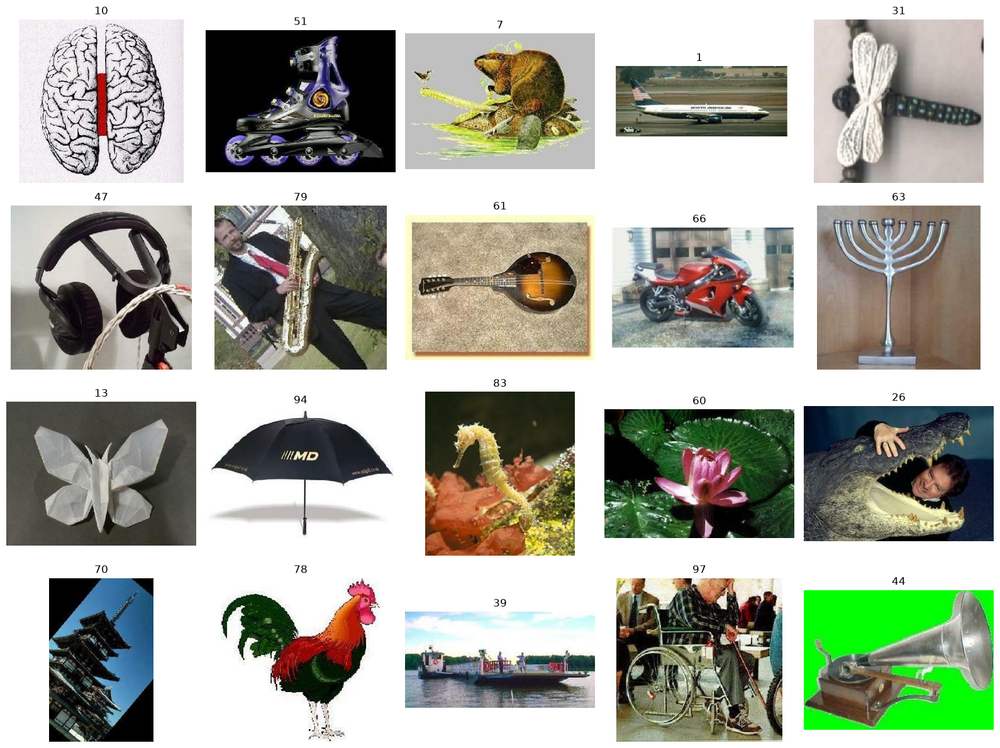

In [20]:
import time
import re
import matplotlib.pyplot as plt

IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

API = "https://datasets-server.huggingface.co/rows"
DATASET = "dpdl-benchmark/caltech101"

session = requests.Session()

selected = {}
offset = 0
batch_size = 100

def safe_name(name):
    return re.sub(r"[^a-zA-Z0-9_-]", "_", str(name).lower())

while len(selected) < 20:
    response = session.get(
        API,
        params={
            "dataset": DATASET,
            "config": "default",
            "split": "train",
            "offset": offset,
            "length": batch_size
        },
        timeout=60
    )
    response.raise_for_status()

    rows = response.json().get("rows", [])

    if not rows:
        print("No more rows available.")
        break

    for item in rows:
        row = item["row"]

        # Caltech-101 typically uses 'label' and 'image'
        label = row.get("label")
        image_info = row.get("image")

        if label is None or image_info is None:
            continue

        if label in selected:
            continue

        try:
            image_url = image_info["src"]

            img_response = session.get(
                image_url,
                timeout=30
            )
            img_response.raise_for_status()

            img = Image.open(
                BytesIO(img_response.content)
            ).convert("RGB")

            # Keep aspect ratio
            img.thumbnail((600, 600))

            filename = f"class_{safe_name(label)}.jpg"
            path = IMAGE_DIR / filename
            img.save(path, "JPEG", quality=90)

            selected[label] = str(path)

            print(
                f"[{len(selected)}/20] "
                f"Class {label}: {img.size}"
            )

        except Exception as e:
            print(f"Failed class {label}: {e}")

        if len(selected) == 20:
            break

    offset += batch_size
    time.sleep(0.5)

print("\nTotal images downloaded:", len(selected))

# Display images
fig, axes = plt.subplots(4, 5, figsize=(16, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, (label, path) in zip(axes.flat, selected.items()):
    ax.imshow(Image.open(path))
    ax.set_title(str(label))

plt.tight_layout()
plt.show()

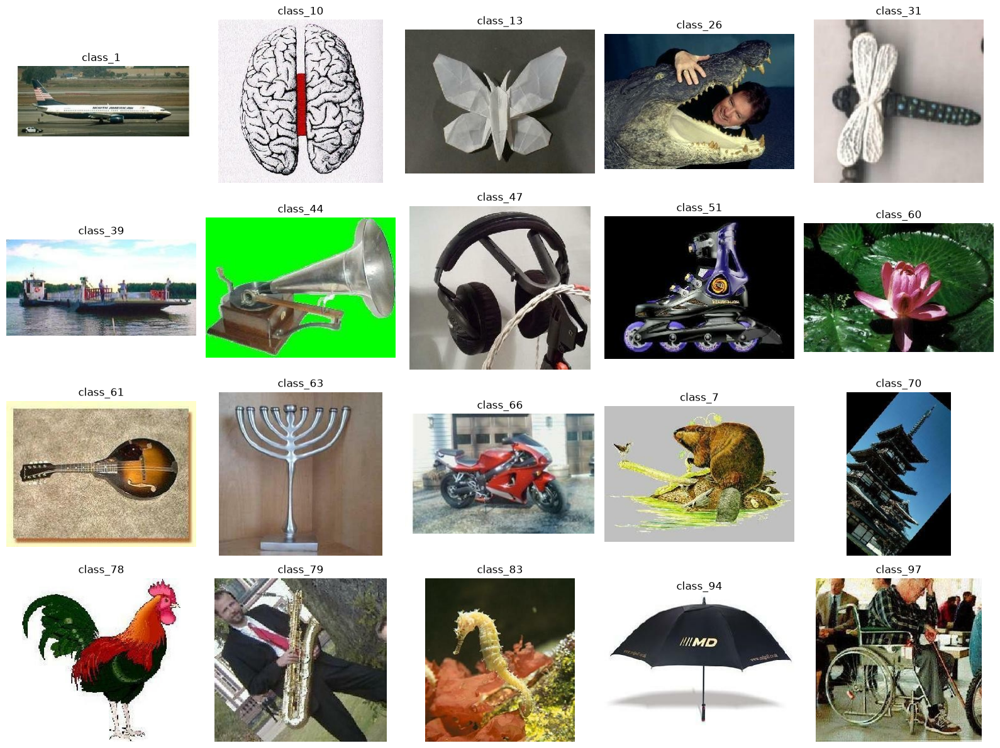

In [21]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

image_paths = sorted(Path("images").glob("*.jpg"))

fig, axes = plt.subplots(4, 5, figsize=(16, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, path in zip(axes.flat, image_paths):
    ax.imshow(Image.open(path))
    ax.set_title(path.stem)

plt.tight_layout()
plt.show()

In [22]:
import torch
from pathlib import Path
from PIL import Image
import torch.nn.functional as F

# Load images directly from images/
# This excludes the evaluation/ subdirectory.
image_paths = sorted(Path("images").glob("*.jpg"))

image_embeddings = []
model.eval()

for path in image_paths:
    img = Image.open(path).convert("RGB")

    inputs = processor(
        images=img,
        return_tensors="pt"
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        features = model.get_image_features(**inputs)

        # Compatibility with Transformers 5.x
        if not isinstance(features, torch.Tensor):
            features = (
                features.pooler_output
                if hasattr(features, "pooler_output")
                else features.image_embeds
            )

    # Normalize embedding
    features = F.normalize(features, p=2, dim=-1)

    image_embeddings.append(features.squeeze(0).cpu())

# Combine all embeddings into one matrix
image_embeddings = torch.stack(image_embeddings)

# Save database
torch.save({
    "paths": [str(p) for p in image_paths],
    "embeddings": image_embeddings
}, "clip_image_database.pt")

print("Number of images:", len(image_paths))
print("Embedding matrix shape:", image_embeddings.shape)
print("Database saved successfully!")

Number of images: 20
Embedding matrix shape: torch.Size([20, 512])
Database saved successfully!


In [23]:
norms = torch.linalg.vector_norm(image_embeddings, dim=1)

print("First 5 embedding norms:", norms[:5])
print("All embeddings normalized:",
      torch.allclose(norms, torch.ones_like(norms), atol=1e-5))

First 5 embedding norms: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
All embeddings normalized: True


Query: a person playing football
1. images/class_97.jpg | similarity: 0.2186
2. images/class_10.jpg | similarity: 0.2179
3. images/class_7.jpg | similarity: 0.2123
4. images/class_39.jpg | similarity: 0.1988
5. images/class_78.jpg | similarity: 0.1864


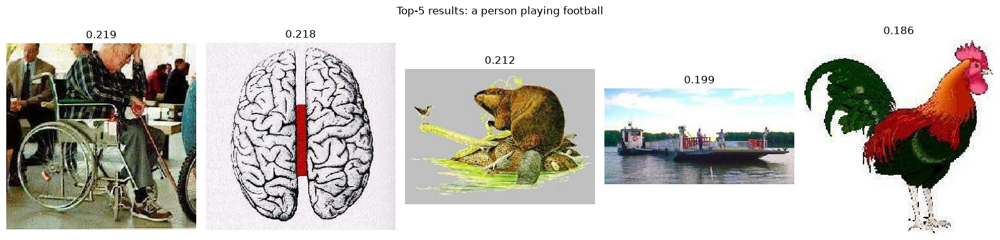

In [24]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

def search_images(query, top_k=5):
    # Convert text query into an embedding
    inputs = processor(
        text=[query],
        return_tensors="pt",
        padding=True
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        text_features = model.get_text_features(**inputs)

        # Handle Transformers 5.x output objects
        if not isinstance(text_features, torch.Tensor):
            text_features = (
                text_features.pooler_output
                if hasattr(text_features, "pooler_output")
                else text_features.text_embeds
            )

    # Normalize the text embedding
    text_features = F.normalize(
        text_features, p=2, dim=-1
    ).cpu()

    # Image embeddings are already normalized
    similarities = (
        image_embeddings @ text_features.squeeze(0)
    )

    # Select the most similar images
    values, indices = torch.topk(
        similarities,
        k=min(top_k, len(image_paths))
    )

    return [
        (str(image_paths[i]), score.item())
        for i, score in zip(indices.tolist(), values)
    ]


# Test the professor's example query
query = "a person playing football"

top_results = search_images(query, top_k=5)

print("Query:", query)
for rank, (path, score) in enumerate(top_results, 1):
    print(f"{rank}. {path} | similarity: {score:.4f}")

# Display the Top-5 images
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, (path, score) in zip(axes, top_results):
    ax.imshow(Image.open(path))
    ax.set_title(f"{score:.3f}")
    ax.axis("off")

plt.suptitle(f"Top-5 results: {query}")
plt.tight_layout()
plt.show()

### Exercise 8 — Answers

**Q20. What is the most similar image?**

The most similar image is **`class_97.jpg`**, showing a person in a wheelchair, with a cosine similarity score of **0.2186**.

**Q21. Is it semantically relevant?**

**No.** Although the image contains a person, it does not show someone playing football. The result is only partially related to the query, because the database does not contain a suitable football image.

**Q22. Why does this method not require image labels?**

Because CLIP converts both images and text into **a shared embedding space**. Images are retrieved by comparing their embeddings with the query embedding using **cosine similarity**, without requiring predefined labels.

**Q23. Give one real-world application of semantic image retrieval.**

A real-world application is **image search in e-commerce platforms**, where users can find products by entering natural-language descriptions instead of selecting predefined categories.

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
Projection Layer
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

### Exercise 9 — Answers

**Q24. What is the role of the vision encoder?**

The **CLIP Vision Encoder** extracts visual features from the input image and converts them into numerical representations (**visual embeddings**) that capture its content.

**Q25. Why is a projection layer required?**

The **projection layer** transforms the visual embeddings into a representation compatible with the language model, allowing it to process visual information alongside text.

**Q26. What is the role of the language model?**

The **language model** combines the visual information with the user's text prompt to generate a **natural-language response**, such as an image description or an answer to a question.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [15]:
%pip install -q -U huggingface_hub

from huggingface_hub import hf_hub_download
from pathlib import Path

REPO_ID = "mys/ggml_llava-v1.5-7b"

MODEL_FILE = "ggml-model-q4_k.gguf"
MMPROJ_FILE = "mmproj-model-f16.gguf"

Path("models").mkdir(exist_ok=True)

model_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=MODEL_FILE,
    local_dir="models"
)

mmproj_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=MMPROJ_FILE,
    local_dir="models"
)

print("Model:", model_path)
print("Projector:", mmproj_path)
print("Download completed!")

Note: you may need to restart the kernel to use updated packages.
Model: /root/research/clip-llava-lab/models/ggml-model-q4_k.gguf
Projector: /root/research/clip-llava-lab/models/mmproj-model-f16.gguf
Download completed!


In [16]:
from huggingface_hub import hf_hub_download
from gguf import GGUFReader

new_mmproj = hf_hub_download(
    repo_id="second-state/Llava-v1.5-7B-GGUF",
    filename="llava-v1.5-7b-mmproj-model-f16.gguf",
    local_dir="models"
)

reader = GGUFReader(new_mmproj)

print("New projector:", new_mmproj)
print("Projector metadata:",
      [key for key in reader.fields if "projector" in key.lower()])

New projector: /root/research/clip-llava-lab/models/llava-v1.5-7b-mmproj-model-f16.gguf
Projector metadata: ['clip.has_llava_projector', 'clip.projector_type']


In [17]:
from llama_cpp import Llama
from llama_cpp.llama_chat_format import Llava15ChatHandler

chat_handler = Llava15ChatHandler(
    clip_model_path=str(new_mmproj),
    verbose=False
)

llava = Llama(
    model_path=str(model_path),
    chat_handler=chat_handler,
    n_ctx=4096,
    n_threads=16,
    n_batch=512,
    n_gpu_layers=0,
    verbose=False
)

print("LLaVA initialized successfully!")

LLaVA initialized successfully!


In [18]:
import base64
import mimetypes
from pathlib import Path

def ask_llava(image_path, question, max_tokens=150):
    image_path = Path(image_path)

    mime_type = mimetypes.guess_type(image_path.name)[0] or "image/jpeg"

    image_base64 = base64.b64encode(
        image_path.read_bytes()
    ).decode("utf-8")

    image_url = f"data:{mime_type};base64,{image_base64}"

    response = llava.create_chat_completion(
        messages=[
            {
                "role": "user",
                "content": [
                    {
                        "type": "image_url",
                        "image_url": {"url": image_url}
                    },
                    {
                        "type": "text",
                        "text": question
                    }
                ]
            }
        ],
        max_tokens=max_tokens,
        temperature=0.1
    )

    return response["choices"][0]["message"]["content"]

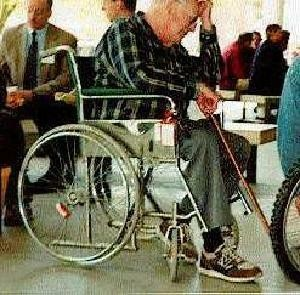

In [19]:
from IPython.display import display
from PIL import Image

image_path = "images/class_97.jpg"

display(Image.open(image_path))

In [21]:
questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

llava_answers = []

for i, question in enumerate(questions, start=1):
    print(f"\nQuestion {i}: {question}")

    answer = ask_llava(image_path, question, max_tokens=180)

    llava_answers.append({
        "Question": question,
        "LLaVA Answer": answer
    })

    print(f"Answer: {answer}")
    print("-" * 60)


Question 1: What is happening in this image?


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What is happening in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 721 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3361 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 795 ms


Answer:  The image features an elderly man sitting in a wheelchair, holding a red leash attached to a bicycle. He appears to be enjoying his time outdoors, possibly in a public area or a park. There are several other people in the scene, some of them sitting on benches and others standing around.

In the background, there are a few cups and a bowl placed on surfaces, suggesting that the people in the area might be having a picnic or enjoying a meal together. The presence of the bicycle and the man's wheelchair indicates that the location is accessible and accommodating for people with different mobility needs.
------------------------------------------------------------

Question 2: How many people are visible?


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: How many people are visible?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 729 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 10261 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 305 ms


Answer: 5 people are visible in the image.
------------------------------------------------------------

Question 3: What objects can you identify?


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What objects can you identify?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 730 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 4332 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 1006 ms


Answer: 1. A man in a wheelchair.
2. A bicycle with a red leash.
3. A dining table.
4. A cup.
5. A bench.
6. A person sitting on a bench.
7. A person sitting on a chair.
8. A person wearing a blue shirt.
9. A person wearing a white shirt.
10. A person wearing a tie.
------------------------------------------------------------

Question 4: Describe the image in detail.


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Describe the image in detail.ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 719 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3594 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 969 ms


Answer:  The image features an elderly man sitting in a wheelchair, wearing a plaid shirt. He is holding a red leash, which is attached to a bicycle. The bicycle is parked next to the man, and there is another person standing nearby.

In the scene, there are also several other people present, some of whom are sitting on chairs and benches. A cup can be seen placed on a surface, and a handbag is located close to one of the people. The overall atmosphere of the image suggests a casual gathering or event where the elderly man is enjoying his time with his bicycle.
------------------------------------------------------------


In [23]:
import pandas as pd

df_ex10 = pd.DataFrame(llava_answers)
display(df_ex10)

,Question,LLaVA Answer
0,What is happening in this image?,The image features an elderly man sitting in ...
1,How many people are visible?,5 people are visible in the image.
2,What objects can you identify?,1. A man in a wheelchair.\n2. A bicycle with a...
3,Describe the image in detail.,The image features an elderly man sitting in ...


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

Selected images:
images/class_1.jpg


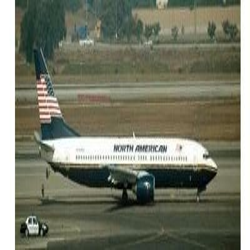

images/class_10.jpg


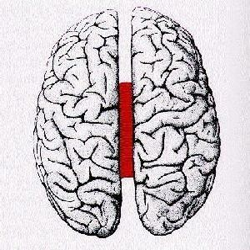

images/class_13.jpg


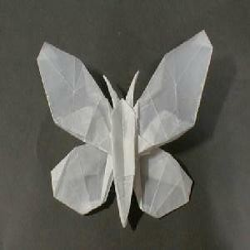

images/class_26.jpg


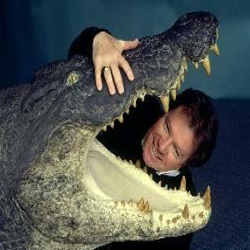

images/class_31.jpg


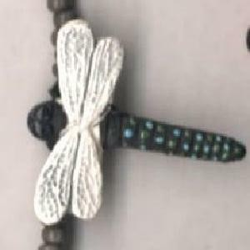

In [25]:
from pathlib import Path
from IPython.display import display
from PIL import Image

# Select five different images from the existing collection
image_paths = sorted(Path("images").glob("class_*.jpg"))[:5]

assert len(image_paths) == 5, "At least five images are required."

questions = [
    "What is the main subject of this image?",
    "How many people are visible in this image?",
    "What objects can you identify?",
    "What is happening in this image?",
    "Describe the image in one sentence."
]

print("Selected images:")
for path in image_paths:
    print(path)
    display(Image.open(path).resize((250, 250)))

In [26]:
import pandas as pd

vqa_results = []

for image_index, image_path in enumerate(image_paths, start=1):

    print(f"\n{'='*60}")
    print(f"IMAGE {image_index}: {image_path.name}")
    print(f"{'='*60}")

    for question_index, question in enumerate(questions, start=1):

        answer = ask_llava(
            image_path,
            question,
            max_tokens=120
        )

        vqa_results.append({
            "Image": image_path.name,
            "Question": question,
            "LLaVA Answer": answer,
            "Human Evaluation": None
        })

        print(f"Q{question_index}: {question}")
        print(f"Answer: {answer}\n")

df_vqa = pd.DataFrame(vqa_results)

#display(df_vqa)


IMAGE 1: class_1.jpg


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What is the main subject of this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 718 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 2999 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 839 ms


Q1: What is the main subject of this image?
Answer:  The main subject of this image is a large passenger jet, specifically a North American airplane, sitting on the runway at an airport.



mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: How many people are visible in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 732 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 14288 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 309 ms


Q2: How many people are visible in this image?
Answer: 1 person is visible in the image, standing near the airplane.



...

mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What is happening in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 722 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 2896 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 1237 ms


Q4: What is happening in this image?
Answer:  The image features a close-up view of a blue and white butterfly wing, which is attached to a piece of jewelry. The butterfly wing is positioned on a table, and it appears to be a part of a necklace or a decorative piece. The wing is the main focus of the image, and it is displayed prominently in the foreground.



mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Describe the image in one sentence.ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 724 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3149 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 539 ms


Q5: Describe the image in one sentence.
Answer: 2 blue and white butterfly wings on a silver chain.



,Image,Question,LLaVA Answer,Human Evaluation
0,class_1.jpg,What is the main subject of this image?,The main subject of this image is a large pas...,None
1,class_1.jpg,How many people are visible in this image?,"1 person is visible in the image, standing nea...",None
2,class_1.jpg,What objects can you identify?,1. A large passenger jet airplane\n2. A truck\...,None
3,class_1.jpg,What is happening in this image?,The image features a large North American air...,None
4,class_1.jpg,Describe the image in one sentence.,"2 airplanes are on the runway, one is a North ...",None
5,class_10.jpg,What is the main subject of this image?,The main subject of this image is a close-up ...,None
6,class_10.jpg,How many people are visible in this image?,0,None
7,class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white backgrou...,None
8,class_10.jpg,What is happening in this image?,The image features a close-up of a human brai...,None
9,class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through th...,None



IMAGE: class_1.jpg


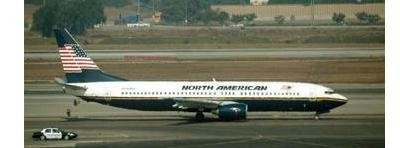

Image,Question,LLaVA Answer,Human Evaluation
class_1.jpg,What is the main subject of this image?,"The main subject of this image is a large passenger jet, specifically a North American airplane, sitting on the runway at an airport.",None
class_1.jpg,How many people are visible in this image?,"1 person is visible in the image, standing near the airplane.",None
class_1.jpg,What objects can you identify?,1. A large passenger jet airplane\n2. A truck\n3. A person\n4. A car\n5. A bus\n6. A tree\n7. A building\n8. A fence\n9. A person with a backpack\n10. A person with a suitcase\n11. A person with a handbag\n12. A person with a cell phone\n13. A person with a tie\n14. A person with a hat\n15. A person with a shirt\n16. A person with a,None
class_1.jpg,What is happening in this image?,"The image features a large North American airplane parked on the runway at an airport. The airplane is positioned on the tarmac, and there are several people around it, possibly attending to the aircraft or preparing for boarding. In addition to the airplane, there are a few cars and a truck visible in the scene, likely providing support services to the airplane. The presence of these vehicles and people suggests that the airplane is either preparing for takeoff or has recently landed.",None
class_1.jpg,Describe the image in one sentence.,"2 airplanes are on the runway, one is a North American plane.",None



IMAGE: class_10.jpg


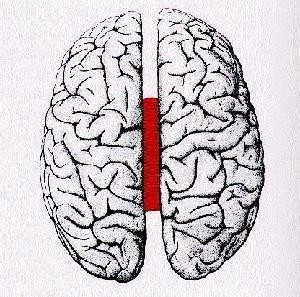

Image,Question,LLaVA Answer,Human Evaluation
class_10.jpg,What is the main subject of this image?,"The main subject of this image is a close-up of a human brain, specifically focusing on the left side of the brain.",None
class_10.jpg,How many people are visible in this image?,0,None
class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white background\n4. A red line on the brain\n5. A white background with a red line on it\n6. A white background with a red line on the brain\n7. A white background with a red line on the brain\n8. A white background with a red line on the brain\n9. A white background with a red line on the brain\n10. A white background with a red line on the brain,None
class_10.jpg,What is happening in this image?,"The image features a close-up of a human brain, with a red line drawn through the center of it. The brain is depicted in a black and white style, which adds a sense of contrast to the image. The red line divides the brain into two distinct sections, creating a visually striking representation of the organ.",None
class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through the center.,None



IMAGE: class_13.jpg


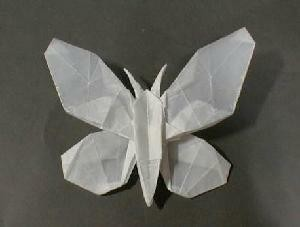

Image,Question,LLaVA Answer,Human Evaluation
class_13.jpg,What is the main subject of this image?,1. A butterfly made out of paper.,None
class_13.jpg,How many people are visible in this image?,0,None
class_13.jpg,What objects can you identify?,1. A butterfly made of paper\n2. A black background or table\n3. A white paper butterfly\n4. A paper butterfly with wings\n5. A paper butterfly with wings and antennae\n6. A paper butterfly with wings and antennae on a black background\n7. A paper butterfly with wings and antennae on a black table\n8. A paper butterfly with wings and antennae on a black surface\n9. A paper butterfly with wings and antennae on a,None
class_13.jpg,What is happening in this image?,"The image features a close-up of a paper butterfly, which is made from a single sheet of paper. The butterfly is folded and cut into the shape of a butterfly, showcasing its intricate details. The paper butterfly is placed on a black background, which emphasizes its shape and texture. The simplicity of the paper butterfly and the black background create a visually appealing and minimalist composition.",None
class_13.jpg,Describe the image in one sentence.,3D paper butterfly with wings and antennae.,None



IMAGE: class_26.jpg


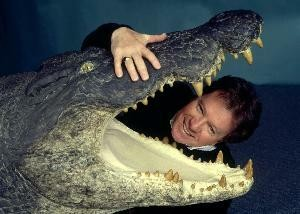

Image,Question,LLaVA Answer,Human Evaluation
class_26.jpg,What is the main subject of this image?,1. A man is the main subject of this image.,None
class_26.jpg,How many people are visible in this image?,1,None
class_26.jpg,What objects can you identify?,1. A man\n2. A crocodile\n3. A black jacket\n4. A white shirt\n5. A pair of glasses\n6. A man's head\n7. A crocodile's mouth\n8. A man's face\n9. A crocodile's teeth\n10. A man's hair\n11. A crocodile's tongue\n12. A man's neck\n13. A crocodile's jaw\n14. A man's smile\n,None
class_26.jpg,What is happening in this image?,"In the image, a man is playfully posing with a large alligator, as if he is being swallowed by its open mouth. The alligator's mouth is wide open, and the man is standing in front of it, making the scene appear humorous and lighthearted. The man is wearing a tie, which adds a touch of formality to the playful moment.",None
class_26.jpg,Describe the image in one sentence.,2 men are standing next to a large alligator.,None



IMAGE: class_31.jpg


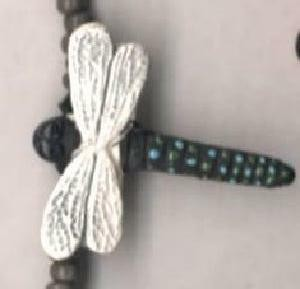

Image,Question,LLaVA Answer,Human Evaluation
class_31.jpg,What is the main subject of this image?,"The main subject of this image is a beaded dragonfly or butterfly charm, which is attached to a bracelet or necklace.",None
class_31.jpg,How many people are visible in this image?,0,None
class_31.jpg,What objects can you identify?,1. A blue and white butterfly or dragonfly charm.\n2. A bead or a small piece of jewelry.\n3. A string or a cord.\n4. A cross or a piece of jewelry.\n5. A white and blue butterfly or dragonfly charm.,None
class_31.jpg,What is happening in this image?,"The image features a close-up view of a blue and white butterfly wing, which is attached to a piece of jewelry. The butterfly wing is positioned on a table, and it appears to be a part of a necklace or a decorative piece. The wing is the main focus of the image, and it is displayed prominently in the foreground.",None
class_31.jpg,Describe the image in one sentence.,2 blue and white butterfly wings on a silver chain.,None


In [27]:
import pandas as pd
from IPython.display import display, HTML
from PIL import Image

# Display full text in pandas tables
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 2000)

for image_path in image_paths:
    print(f"\n{'=' * 70}")
    print(f"IMAGE: {image_path.name}")
    print(f"{'=' * 70}")

    display(Image.open(image_path))

    image_results = df_vqa[
        df_vqa["Image"] == image_path.name
    ].copy()

    display(
        HTML(
            image_results.to_html(
                index=False,
                escape=True
            )
        )
    )

In [28]:
from IPython.display import clear_output

evaluations = []

for image_path in image_paths:

    clear_output(wait=True)

    print(f"Evaluating: {image_path.name}")
    display(Image.open(image_path))

    image_results = df_vqa[df_vqa["Image"] == image_path.name]

    for _, row in image_results.iterrows():

        print("\nQuestion:", row["Question"])
        print("LLaVA Answer:", row["LLaVA Answer"])

        while True:
            score = input("Correct? (1 = Yes, 0 = No): ").strip()

            if score in ("0", "1"):
                evaluations.append(int(score))
                break

            print("Please enter 1 or 0.")

df_vqa["Human Evaluation"] = evaluations

clear_output(wait=True)
display(df_vqa)

,Image,Question,LLaVA Answer,Human Evaluation
0,class_1.jpg,What is the main subject of this image?,"The main subject of this image is a large passenger jet, specifically a North American airplane, sitting on the runway at an airport.",1
1,class_1.jpg,How many people are visible in this image?,"1 person is visible in the image, standing near the airplane.",1
2,class_1.jpg,What objects can you identify?,1. A large passenger jet airplane\n2. A truck\n3. A person\n4. A car\n5. A bus\n6. A tree\n7. A building\n8. A fence\n9. A person with a backpack\n10. A person with a suitcase\n11. A person with a handbag\n12. A person with a cell phone\n13. A person with a tie\n14. A person with a hat\n15. A person with a shirt\n16. A person with a,0
3,class_1.jpg,What is happening in this image?,"The image features a large North American airplane parked on the runway at an airport. The airplane is positioned on the tarmac, and there are several people around it, possibly attending to the aircraft or preparing for boarding. In addition to the airplane, there are a few cars and a truck visible in the scene, likely providing support services to the airplane. The presence of these vehicles and people suggests that the airplane is either preparing for takeoff or has recently landed.",0
4,class_1.jpg,Describe the image in one sentence.,"2 airplanes are on the runway, one is a North American plane.",0
5,class_10.jpg,What is the main subject of this image?,"The main subject of this image is a close-up of a human brain, specifically focusing on the left side of the brain.",1
6,class_10.jpg,How many people are visible in this image?,0,1
7,class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white background\n4. A red line on the brain\n5. A white background with a red line on it\n6. A white background with a red line on the brain\n7. A white background with a red line on the brain\n8. A white background with a red line on the brain\n9. A white background with a red line on the brain\n10. A white background with a red line on the brain,1
8,class_10.jpg,What is happening in this image?,"The image features a close-up of a human brain, with a red line drawn through the center of it. The brain is depicted in a black and white style, which adds a sense of contrast to the image. The red line divides the brain into two distinct sections, creating a visually striking representation of the organ.",1
9,class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through the center.,1


In [29]:
correct_answers = int(df_vqa["Human Evaluation"].sum())
total_questions = len(df_vqa)

vqa_accuracy = (correct_answers / total_questions) * 100

print(f"Total questions: {total_questions}")
print(f"Correct answers: {correct_answers}")
print(f"Incorrect answers: {total_questions - correct_answers}")
print(f"VQA Accuracy: {vqa_accuracy:.2f}%")

Total questions: 25
Correct answers: 18
Incorrect answers: 7
VQA Accuracy: 72.00%


In [30]:
df_vqa.to_csv("llava_vqa_evaluation.csv", index=False)

print("Results saved to llava_vqa_evaluation.csv")
display(df_vqa)

Results saved to llava_vqa_evaluation.csv


,Image,Question,LLaVA Answer,Human Evaluation
0,class_1.jpg,What is the main subject of this image?,"The main subject of this image is a large passenger jet, specifically a North American airplane, sitting on the runway at an airport.",1
1,class_1.jpg,How many people are visible in this image?,"1 person is visible in the image, standing near the airplane.",1
2,class_1.jpg,What objects can you identify?,1. A large passenger jet airplane\n2. A truck\n3. A person\n4. A car\n5. A bus\n6. A tree\n7. A building\n8. A fence\n9. A person with a backpack\n10. A person with a suitcase\n11. A person with a handbag\n12. A person with a cell phone\n13. A person with a tie\n14. A person with a hat\n15. A person with a shirt\n16. A person with a,0
3,class_1.jpg,What is happening in this image?,"The image features a large North American airplane parked on the runway at an airport. The airplane is positioned on the tarmac, and there are several people around it, possibly attending to the aircraft or preparing for boarding. In addition to the airplane, there are a few cars and a truck visible in the scene, likely providing support services to the airplane. The presence of these vehicles and people suggests that the airplane is either preparing for takeoff or has recently landed.",0
4,class_1.jpg,Describe the image in one sentence.,"2 airplanes are on the runway, one is a North American plane.",0
5,class_10.jpg,What is the main subject of this image?,"The main subject of this image is a close-up of a human brain, specifically focusing on the left side of the brain.",1
6,class_10.jpg,How many people are visible in this image?,0,1
7,class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white background\n4. A red line on the brain\n5. A white background with a red line on it\n6. A white background with a red line on the brain\n7. A white background with a red line on the brain\n8. A white background with a red line on the brain\n9. A white background with a red line on the brain\n10. A white background with a red line on the brain,1
8,class_10.jpg,What is happening in this image?,"The image features a close-up of a human brain, with a red line drawn through the center of it. The brain is depicted in a black and white style, which adds a sense of contrast to the image. The red line divides the brain into two distinct sections, creating a visually striking representation of the organ.",1
9,class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through the center.,1


## Exercise 11 — Answers

#### Q27 — What is VQA accuracy?

In our experiment, LLaVA correctly answered **18 out of 25 questions** across five images.

**Result:** LLaVA achieved a VQA accuracy of **72%** based on human evaluation.

#### Q28 — Which types of questions are difficult for LLaVA?

Our experiment showed that LLaVA performed well on recognizing main subjects and answering simple counting questions, but struggled with:

- **Detailed object identification:** It sometimes invented objects that were not present in the images.
- **Scene understanding:** It occasionally described activities or situations without sufficient visual evidence.
- **Accurate image descriptions:** It sometimes introduced incorrect details, such as describing two airplanes or two people when only one was visible.
- **Visual hallucination:** It generated plausible but incorrect information about objects, people, and their surroundings.

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

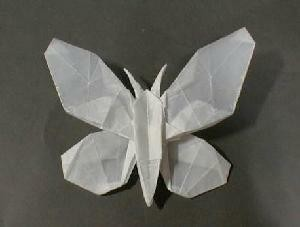

In [20]:
from PIL import Image
from IPython.display import display

image_path_ex12 = "images/class_13.jpg"

display(Image.open(image_path_ex12))

In [32]:
questions_ex12 = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]

answers_ex12 = []

for i, question in enumerate(questions_ex12, start=1):
    answer = ask_llava(image_path_ex12, question, max_tokens=120)

    answers_ex12.append({
        "Question": question,
        "LLaVA Answer": answer
    })

    print(f"Q{i}: {question}")
    print(f"Answer: {answer}")
    print("-" * 60)

mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Is there a bicycle in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 722 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 2465 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 650 ms
mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_me

Q1: Is there a bicycle in this image?
Answer: 0
------------------------------------------------------------


encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 723 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 15730 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 773 ms
mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Where is the bicycle located?ASSISTANT: 


Q2: What color is the bicycle?
Answer: 0
------------------------------------------------------------


encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 719 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 2906 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 868 ms


Q3: Where is the bicycle located?
Answer: 1. The bicycle is located in a room.
------------------------------------------------------------


In [33]:
import pandas as pd

df_ex12 = pd.DataFrame(answers_ex12)
pd.set_option("display.max_colwidth", None)
display(df_ex12)

,Question,LLaVA Answer
0,Is there a bicycle in this image?,0
1,What color is the bicycle?,0
2,Where is the bicycle located?,1. The bicycle is located in a room.


In [34]:
df_ex12.to_csv("llava_hallucination_results.csv", index=False)
print("Results saved successfully.")

Results saved successfully.


## Exercise 12 — Answers

#### Q29 — Does the bicycle actually exist?

No. The selected image (`class_13.jpg`) shows a white paper butterfly against a dark background. There is **no bicycle** in the image.

#### Q30 — Did LLaVA invent information?

Yes, LLaVA partially hallucinated information.

- **Question 1:** "Is there a bicycle in this image?" → `0` (No, correct).
- **Question 2:** "What color is the bicycle?" → `0` (No bicycle color identified).
- **Question 3:** "Where is the bicycle located?" → "The bicycle is located in a room." (Incorrect).

Although LLaVA did not identify a bicycle in the first two answers, it **invented a location for a nonexistent bicycle** in the third answer.

#### Q31 — What is a visual hallucination?

A visual hallucination occurs when a vision-language model generates information that is **not supported by the image**.

#### Q32 — Why can a multimodal model hallucinate?

Multimodal models can hallucinate for several reasons:

- **Language-model bias:** The model generates plausible text based on learned patterns instead of strictly verifying visual evidence.
- **Leading questions:** Questions such as "Where is the bicycle located?" implicitly assume that a bicycle exists.
- **Visual-language misalignment:** Visual features may not be perfectly aligned with the generated text.
- **Limited visual grounding:** The model may rely on linguistic assumptions rather than actual image content.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

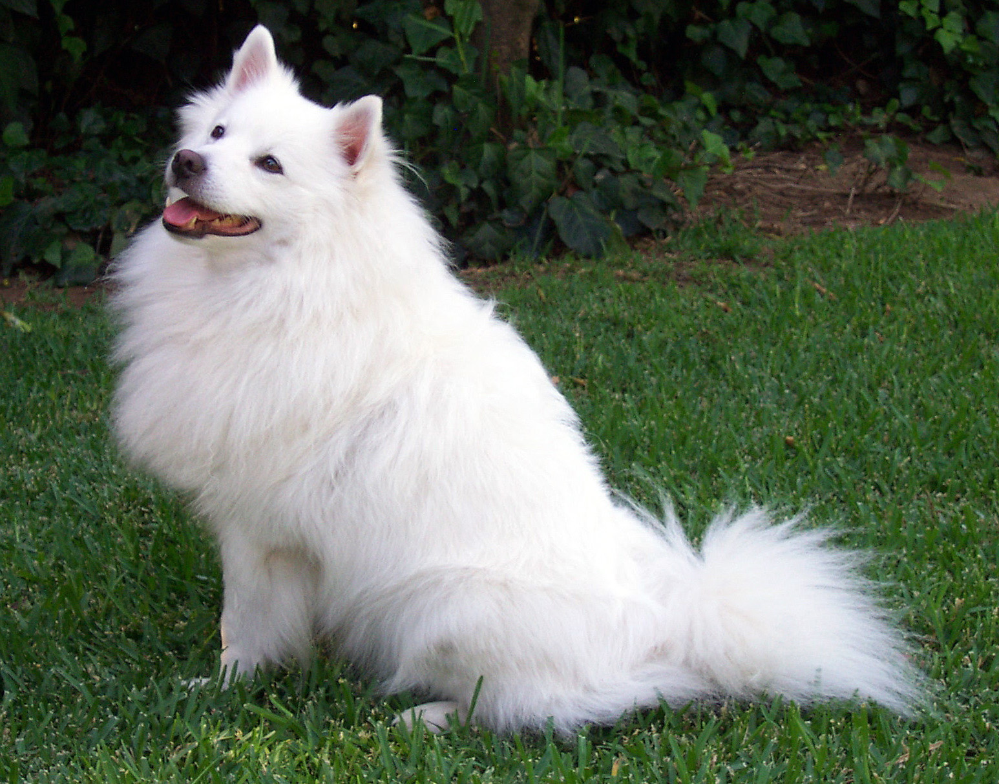

In [35]:
from pathlib import Path
from PIL import Image
from IPython.display import display

image_path_ex13 = "image.jpg"

assert Path(image_path_ex13).exists(), "Image not found!"

image_ex13 = Image.open(image_path_ex13).convert("RGB")
display(image_ex13)

In [37]:
import torch
import pandas as pd
from transformers import CLIPModel, CLIPProcessor

# Load CLIP model and processor
device = "cuda" if torch.cuda.is_available() else "cpu"

clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
).to(device)

clip_processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

# Candidate classes
prompts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a horse"
]

# Process the image and text
inputs = clip_processor(
    text=prompts,
    images=image_ex13,
    return_tensors="pt",
    padding=True
)

inputs = {key: value.to(device) for key, value in inputs.items()}

# Perform zero-shot classification
clip_model.eval()

with torch.no_grad():
    outputs = clip_model(**inputs)
    probabilities = outputs.logits_per_image.softmax(dim=1)[0].cpu()

# Display results
df_clip_ex13 = pd.DataFrame({
    "Description": prompts,
    "Probability": probabilities.numpy()
})

display(df_clip_ex13)

best_index = probabilities.argmax().item()

print("CLIP prediction:", prompts[best_index])
print(f"Probability: {probabilities[best_index]:.2%}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

,Description,Probability
0,a photo of a cat,0.003818
1,a photo of a dog,0.990498
2,a photo of a horse,0.005685


CLIP prediction: a photo of a dog
Probability: 99.05%


In [38]:
question_ex13 = "What animal is present in the image? Describe its appearance."

llava_answer_ex13 = ask_llava(
    image_path_ex13,
    question_ex13,
    max_tokens=180
)

print("Question:", question_ex13)
print("\nLLaVA answer:")
print(llava_answer_ex13)

mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What animal is present in the image? Describe its appearance.ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 719 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3017 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 638 ms


Question: What animal is present in the image? Describe its appearance.

LLaVA answer:
1. A white dog is present in the image. It has a fluffy, long coat and is sitting on the grass.


In [39]:
comparison = pd.DataFrame({
    "Property": [
        "Input",
        "Main output",
        "Zero-shot classification",
        "Image retrieval",
        "Text generation",
        "VQA",
        "Open-ended response"
    ],
    "CLIP": [
        "Image + candidate text descriptions",
        "Image-text similarity scores",
        "Yes, using candidate class descriptions",
        "Yes, through image-text embeddings",
        "No, not a generative model",
        "Not directly",
        "No"
    ],
    "LLaVA": [
        "Image + natural-language question",
        "Generated natural-language response",
        "Possible through prompting",
        "Not a native retrieval model",
        "Yes",
        "Yes",
        "Yes"
    ]
})

display(comparison)

,Property,CLIP,LLaVA
0,Input,Image + candidate text descriptions,Image + natural-language question
1,Main output,Image-text similarity scores,Generated natural-language response
2,Zero-shot classification,"Yes, using candidate class descriptions",Possible through prompting
3,Image retrieval,"Yes, through image-text embeddings",Not a native retrieval model
4,Text generation,"No, not a generative model",Yes
5,VQA,Not directly,Yes
6,Open-ended response,No,Yes


## Exercise 13 — Answers

#### Q33 — Which model is better suited to image classification?

**CLIP** is better suited to zero-shot image classification because it compares an image with candidate text descriptions using similarity scores.

In our experiment, CLIP correctly classified the dog image with the following probabilities:

- **Dog:** 99.05%
- **Horse:** 0.57%
- **Cat:** 0.38%

#### Q34 — Which model is better for image description?

**LLaVA** is better suited to image description because it can generate detailed natural-language explanations about the objects, appearance, and context of an image.

CLIP, in contrast, calculates image-text similarity scores without generating descriptive text.

#### Q35 — Which model is better for visual question answering?

**LLaVA** is better suited to Visual Question Answering (VQA) because it can interpret images and generate answers to natural-language questions.

CLIP cannot directly generate open-ended answers.

#### Q36 — Explain the fundamental difference between CLIP and LLaVA.

**CLIP** is a contrastive vision-language model that learns a shared embedding space for images and text. It is primarily designed for:

- Zero-shot image classification.
- Image-text similarity.
- Image retrieval.

**LLaVA** is a generative multimodal model that combines a vision encoder, a projection layer, and a large language model (LLM). It is designed for:

- Image description.
- Visual Question Answering.
- Open-ended visual reasoning.
- Natural-language response generation.


# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

# Final Mini-Project — Multimodal Image Assistant

## 1. Project Objective

The objective of this mini-project is to develop a small **Multimodal Image Assistant** by combining **CLIP** and **LLaVA**.

The assistant supports two modes:

1. **Image Question Answering:** The user provides an image and asks a natural-language question. LLaVA generates an answer.
2. **Image Retrieval + Question Answering:** The user enters a text query. CLIP retrieves the most relevant images, and LLaVA answers a question about one selected result.

## 2. System Architecture

### Mode A — Image Question Answering

Image + Question → LLaVA → Generated Answer

### Mode B — Image Retrieval + Question Answering

Text Query → CLIP → Top-k Retrieved Images → Selected Image + Question → LLaVA → Generated Answer

## 3. Implementation

The project was implemented in Python in Jupyter Notebook.

- **CLIP (ViT-B/32)** is used for text-to-image retrieval.
- **LLaVA 1.5 7B (quantized)** is used for visual question answering.
- The image database contains 20 indexed images from previous exercises.

The assistant was implemented as a notebook-based interactive workflow using Python functions.

## 4. Demonstration and Results

### Mode A

A direct question was asked about an image (`image.jpg`), and LLaVA generated a natural-language answer describing the content of the image.

### Mode B

A text query was used to retrieve the most relevant images with CLIP. Then, one of the retrieved images was selected, and LLaVA answered a natural-language question about it.

This demonstrates the integration of retrieval and question answering in one multimodal assistant.

## 5. Conclusion

This mini-project shows how **CLIP** and **LLaVA** can be combined in a single assistant.

- **CLIP** is effective for image retrieval through shared image-text embeddings.
- **LLaVA** is effective for visual question answering and image description.

The main limitations are:
- the small size of the image database,
- retrieval errors when the query is ambiguous,
- slower CPU inference,
- and possible hallucinations in LLaVA answers.

In [47]:
%pip show jupyterlab_widgets

Name: jupyterlab_widgets
Version: 3.0.17
Summary: Jupyter interactive widgets for JupyterLab
Home-page: https://github.com/jupyter-widgets/ipywidgets
Author: 
Author-email: Jupyter Development Team <jupyter@googlegroups.com>
License: Copyright (c) 2015 Project Jupyter Contributors
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

1. Redistributions of source code must retain the above copyright notice, this
   list of conditions and the following disclaimer.

2. Redistributions in binary form must reproduce the above copyright notice,
   this list of conditions and the following disclaimer in the documentation
   and/or other materials provided with the distribution.

3. Neither the name of the copyright holder nor the names of its
   contributors may be used to endorse or promote products derived from
   this software without specific prior written permission.

THIS SOFT

In [1]:
import torch
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"

clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
).to(device)

clip_processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

clip_model.eval()

print("CLIP restored successfully!")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP restored successfully!


In [2]:
from llama_cpp import Llama
from llama_cpp.llama_chat_format import Llava15ChatHandler

chat_handler = Llava15ChatHandler(
    clip_model_path="models/llava-v1.5-7b-mmproj-model-f16.gguf",
    verbose=False
)

llava = Llama(
    model_path="models/ggml-model-q4_k.gguf",
    chat_handler=chat_handler,
    n_ctx=4096,
    n_threads=16,
    n_batch=512,
    n_gpu_layers=0,
    verbose=False
)

print("LLaVA restored successfully!")

LLaVA restored successfully!


In [3]:
import base64
import mimetypes
from pathlib import Path

def ask_llava(image_path, question, max_tokens=150):
    image_path = Path(image_path)

    mime_type = mimetypes.guess_type(image_path.name)[0] or "image/jpeg"

    image_base64 = base64.b64encode(
        image_path.read_bytes()
    ).decode("utf-8")

    image_url = f"data:{mime_type};base64,{image_base64}"

    response = llava.create_chat_completion(
        messages=[
            {
                "role": "user",
                "content": [
                    {
                        "type": "image_url",
                        "image_url": {"url": image_url}
                    },
                    {
                        "type": "text",
                        "text": question
                    }
                ]
            }
        ],
        max_tokens=max_tokens,
        temperature=0.1
    )

    return response["choices"][0]["message"]["content"]

print("LLaVA question-answering function restored!")

LLaVA question-answering function restored!


In [4]:
print("CLIP:", "Ready" if "clip_model" in globals() else "Missing")
print("CLIP processor:", "Ready" if "clip_processor" in globals() else "Missing")
print("LLaVA:", "Ready" if "llava" in globals() else "Missing")
print("ask_llava:", "Ready" if callable(globals().get("ask_llava")) else "Missing")

CLIP: Ready
CLIP processor: Ready
LLaVA: Ready
ask_llava: Ready


In [5]:
%pip install -q ipywidgets

import torch
import numpy as np
from pathlib import Path
from PIL import Image
from IPython.display import display, clear_output
import ipywidgets as widgets

# Verify previously initialized models
assert "clip_model" in globals(), "Run Exercise 13's CLIP model-loading cell first."
assert "clip_processor" in globals(), "Run Exercise 13's CLIP processor-loading cell first."
assert "ask_llava" in globals(), "Run Exercise 10's LLaVA setup cells first."

device = next(clip_model.parameters()).device
clip_model.eval()

print("CLIP ready on:", device)
print("LLaVA function ready:", callable(ask_llava))

Note: you may need to restart the kernel to use updated packages.
CLIP ready on: cpu
LLaVA function ready: True


In [6]:
def search_images(query, top_k=5):
    inputs = clip_processor(
        text=[query],
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(device)

    with torch.inference_mode():
        text_features = clip_model.get_text_features(**inputs)

        if not isinstance(text_features, torch.Tensor):
            text_features = text_features.pooler_output

        text_features = text_features / text_features.norm(
            dim=-1,
            keepdim=True
        )

    similarities = (
        image_database_embeddings @ text_features.cpu().T
    ).squeeze(-1)

    scores, indices = torch.topk(
        similarities,
        k=min(top_k, len(image_database_paths))
    )

    return [
        {
            "path": image_database_paths[index],
            "score": float(score)
        }
        for score, index in zip(
            scores.tolist(),
            indices.tolist()
        )
    ]

In [8]:
from pathlib import Path
from PIL import Image
import torch

image_database_paths = sorted(Path("images").glob("class_*.jpg"))

assert len(image_database_paths) >= 5, "At least 5 images are required."

image_vectors = []

clip_model.eval()

with torch.inference_mode():
    for path in image_database_paths:
        image = Image.open(path).convert("RGB")

        inputs = clip_processor(
            images=image,
            return_tensors="pt"
        ).to(device)

        features = clip_model.get_image_features(**inputs)

        if not isinstance(features, torch.Tensor):
            features = features.pooler_output

        features = features / features.norm(dim=-1, keepdim=True)

        image_vectors.append(features.cpu())

image_database_embeddings = torch.cat(image_vectors, dim=0)

print("Images indexed:", len(image_database_paths))
print("Embeddings shape:", image_database_embeddings.shape)

Images indexed: 20
Embeddings shape: torch.Size([20, 512])


In [14]:
from PIL import Image
from IPython.display import display

def multimodal_qa(image_path, question):
    print("Selected image:", image_path)
    display(Image.open(image_path).convert("RGB"))

    print("\nQuestion:", question)

    answer = ask_llava(image_path, question, max_tokens=180)

    print("\nLLaVA Answer:")
    print(answer)

    return answer

In [15]:
from PIL import Image
from IPython.display import display

def multimodal_search_and_qa(query, question, top_k=5, selected_rank=1):
    print("Search query:", query)

    results = search_images(query, top_k=top_k)

    print("\nTop retrieved images:")
    for i, item in enumerate(results, start=1):
        print(f"{i}. {item['path'].name} | similarity: {item['score']:.4f}")
        display(Image.open(item["path"]).convert("RGB"))

    selected = results[selected_rank - 1]
    selected_path = str(selected["path"])

    print(f"\nSelected result: Rank {selected_rank} -> {selected['path'].name}")
    print("Question:", question)

    answer = ask_llava(selected_path, question, max_tokens=180)

    print("\nLLaVA Answer:")
    print(answer)

    return results, selected_path, answer

Selected image: image.jpg


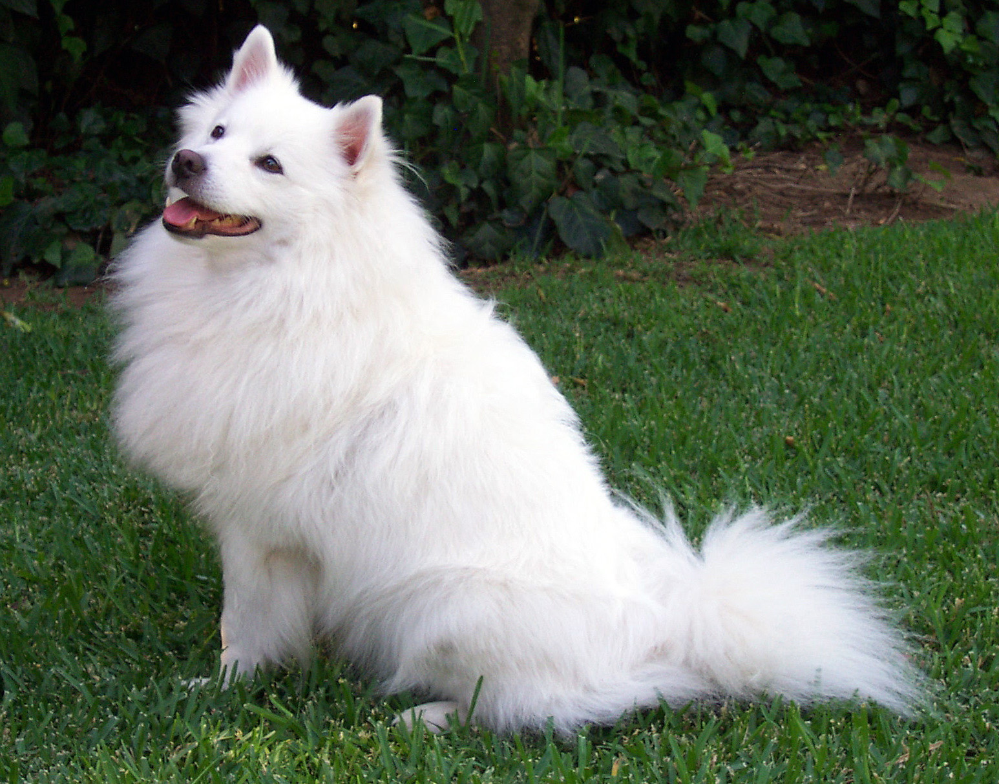


Question: What animal is visible in this image and how would you describe it?


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What animal is visible in this image and how would you describe it?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 727 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 2869 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 1288 ms



LLaVA Answer:
 In the image, a white dog is visible. It is a large, fluffy, and furry dog, possibly a breed like a Samoyed or a similar breed known for its thick, white fur. The dog appears to be sitting or laying down in a grassy field, possibly enjoying the outdoors or taking a break.


In [16]:
# Mode A: direct image question answering
answer_mode_a = multimodal_qa(
    image_path="image.jpg",
    question="What animal is visible in this image and how would you describe it?"
)

Search query: a paper butterfly

Top retrieved images:
1. class_13.jpg | similarity: 0.3461


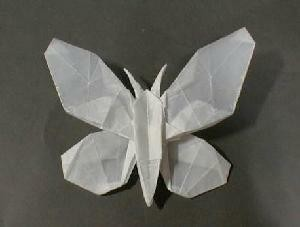

2. class_31.jpg | similarity: 0.2678


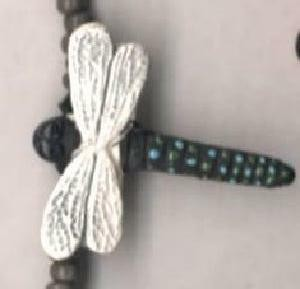

3. class_60.jpg | similarity: 0.2016


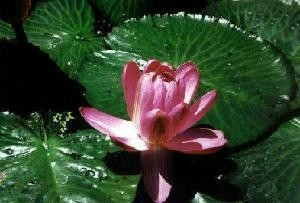

4. class_70.jpg | similarity: 0.1975


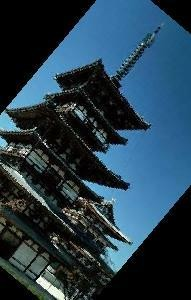

5. class_61.jpg | similarity: 0.1833


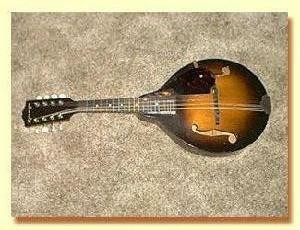


Selected result: Rank 1 -> class_13.jpg
Question: What material is this object made of?


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What material is this object made of?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 722 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 5596 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 15622 ms



LLaVA Answer:
100% Paper


In [17]:
# Mode B: CLIP retrieval + LLaVA question answering
results_mode_b, selected_image_mode_b, answer_mode_b = multimodal_search_and_qa(
    query="a paper butterfly",
    question="What material is this object made of?",
    top_k=5,
    selected_rank=1
)

# Final Laboratory Conclusion

This laboratory explored two complementary vision-language models, **CLIP** and **LLaVA**, through practical experiments involving image classification, semantic retrieval, visual question answering, and multimodal reasoning.

### 1. CLIP — Classification and Image Retrieval

CLIP demonstrated strong capabilities in matching images with natural-language descriptions through a shared embedding space.

- **Zero-shot classification:** Achieved **100% accuracy (10/10)** in the cat/dog classification experiment.
- **Prompt engineering:** Demonstrated how different text descriptions influence image-text similarity scores.
- **Image retrieval:** Successfully implemented semantic similarity search over a database of 20 images using 512-dimensional embeddings.
- **Model comparison:** Correctly identified a dog with **99.05% probability** among three candidate classes.

These experiments demonstrated CLIP's effectiveness for zero-shot classification and image-text retrieval without task-specific training.

### 2. LLaVA — Visual Understanding and Question Answering

LLaVA demonstrated the ability to interpret images and generate natural-language responses.

- **Image description:** Generated detailed descriptions of visual scenes.
- **Visual Question Answering:** Achieved **72% accuracy (18/25)** across five images and 25 questions, based on human evaluation.
- **Visual hallucination:** Invented a location for a nonexistent bicycle, illustrating a limitation of generative multimodal models.

These results highlight LLaVA's ability to perform open-ended visual tasks while demonstrating that fluent responses are not always factually accurate.

### 3. CLIP vs LLaVA

The experiments highlighted the fundamental differences between the two architectures:

- **CLIP** uses contrastive learning to align image and text representations, making it suitable for classification and retrieval.
- **LLaVA** combines a vision encoder, a projection layer, and a large language model to generate descriptive and contextual answers about images.

The models are therefore complementary rather than interchangeable.

### 4. Final Mini-Project — Multimodal Image Assistant

The final mini-project combined CLIP and LLaVA into a single multimodal assistant supporting two workflows:

1. **Direct Image Question Answering:** An image and question are processed by LLaVA to generate a natural-language response.
2. **Image Retrieval + Question Answering:** CLIP retrieves relevant images from a text query, and LLaVA answers questions about a selected image.

This architecture illustrates how retrieval-based and generative AI techniques can be integrated into a practical multimodal application.

### 5. Limitations and Future Improvements

The main limitations identified during the laboratory include:

- The limited size and diversity of the image database.
- Sensitivity of CLIP similarity scores to prompt wording.
- Visual hallucinations and inaccurate details in LLaVA responses.
- Relatively slow inference when running large multimodal models on CPU.

Future improvements could include expanding the image dataset, optimizing inference with GPU acceleration, improving retrieval accuracy, and introducing mechanisms to verify generated answers against visual evidence.

### Overall Conclusion

This laboratory provided practical experience with both **contrastive and generative multimodal AI architectures**.

CLIP proved effective for zero-shot classification and semantic image retrieval, while LLaVA enabled natural-language image understanding and visual question answering.

The experimental results (**100% CLIP classification accuracy** and **72% LLaVA VQA accuracy**) illustrate their capabilities on the selected evaluation datasets, although